Офлайн-пересчёт накопленной контрольной точки 300 задач из сохранённых разборов и аудитов. Новых агентов и сети нет; изменение исходных хешей останавливает пересчёт.

In [1]:
import sys
from pathlib import Path
from IPython.display import display, Image, Markdown
root = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'scripts/fipi_checkpoint300.py').is_file())
sys.path.insert(0, str(root / 'scripts'))
import fipi_checkpoint300 as cp
data = cp.collect()
assert data['input_digest'] == '780f381a96b7f0284cbbc92d32ccdc535d79bf1cc0ae07768eefcec9e88d5e8f', 'Saved inputs changed: use the code version recorded for this snapshot'
summary, tables = cp.metrics(data)
checks = cp.self_checks(data)
report_path = root / 'data/annotation/analyses/2026-11-10-bogdan108-checkpoint-300-v1'
if not report_path.exists():
    report_path = report_path.with_name(report_path.name + '.building')
checks


Frozen bytes verified, including archived paths.


{'eda100_summary_reproduced': True,
 'eda100_frequencies_reproduced': True,
 'eda150_node_frequencies_reproduced': True,
 'eda150_included_tasks': 148,
 'eda200_summary_reproduced': True,
 'eda200_frequencies_reproduced': True,
 'next_b1_4_rows_equal_eda250_collector': True,
 'eda250_summary_reproduced': True,
 'eda250_frequencies_reproduced': True}

In [2]:
lines = ['| Слой | Отобрано | В частотах | Подтверждённых узлов | Единичные |', '|---|---:|---:|---:|---:|']
for key, name in cp.POPULATIONS.items():
    s = summary[key]
    lines.append(f"| {name} | {s['selected_n']} | {s['included_n']} | {s['confirmed_catalog_nodes']} | {s['singleton_nodes']['numerator']} |")
display(Markdown('\n'.join(lines)))


| Слой | Отобрано | В частотах | Подтверждённых узлов | Единичные |
|---|---:|---:|---:|---:|
| Исходные 50: редакторские связи | 50 | 49 | 136 | 101 |
| Первые 50 новых (запуск 2026-11-02): агентный аудит | 50 | 49 | 48 | 30 |
| Бронь #2, 100 задач (партии 5–12): агентный аудит | 100 | 100 | 65 | 34 |
| Бронь #2, партия 5: Opus, уровень рассуждений по умолчанию | 15 | 15 | 24 | 19 |
| Бронь #2, партии 6–12: Opus, effort low | 85 | 85 | 54 | 29 |
| Бронь #4, 100 задач (партии 1–8): Opus, effort low | 100 | 100 | 61 | 35 |
| Бронь #4, партии 1–4 (50 задач, вошли в EDA-250) | 50 | 50 | 40 | 27 |
| Бронь #4, партии 5–8 (50 задач) | 50 | 50 | 39 | 23 |
| Все новые 250: агентный аудит | 250 | 249 | 90 | 25 |
| Смешанный накопленный корпус 300 | 300 | 298 | 139 | 46 |

In [3]:
{k: summary[k]['audit_statuses'] for k in ('team_b6_12_low', 'next_b1_4', 'next_b5_8', 'next100')}

{'team_b6_12_low': {'match': {'numerator': 113, 'denominator': 299},
  'new_candidate': {'numerator': 110, 'denominator': 299},
  'needs_split': {'numerator': 59, 'denominator': 299},
  'uncertain': {'numerator': 17, 'denominator': 299}},
 'next_b1_4': {'match': {'numerator': 59, 'denominator': 190},
  'new_candidate': {'numerator': 84, 'denominator': 190},
  'needs_split': {'numerator': 29, 'denominator': 190},
  'uncertain': {'numerator': 18, 'denominator': 190}},
 'next_b5_8': {'match': {'numerator': 63, 'denominator': 169},
  'new_candidate': {'numerator': 66, 'denominator': 169},
  'needs_split': {'numerator': 23, 'denominator': 169},
  'uncertain': {'numerator': 17, 'denominator': 169}},
 'next100': {'match': {'numerator': 122, 'denominator': 359},
  'new_candidate': {'numerator': 150, 'denominator': 359},
  'needs_split': {'numerator': 52, 'denominator': 359},
  'uncertain': {'numerator': 35, 'denominator': 359}}}

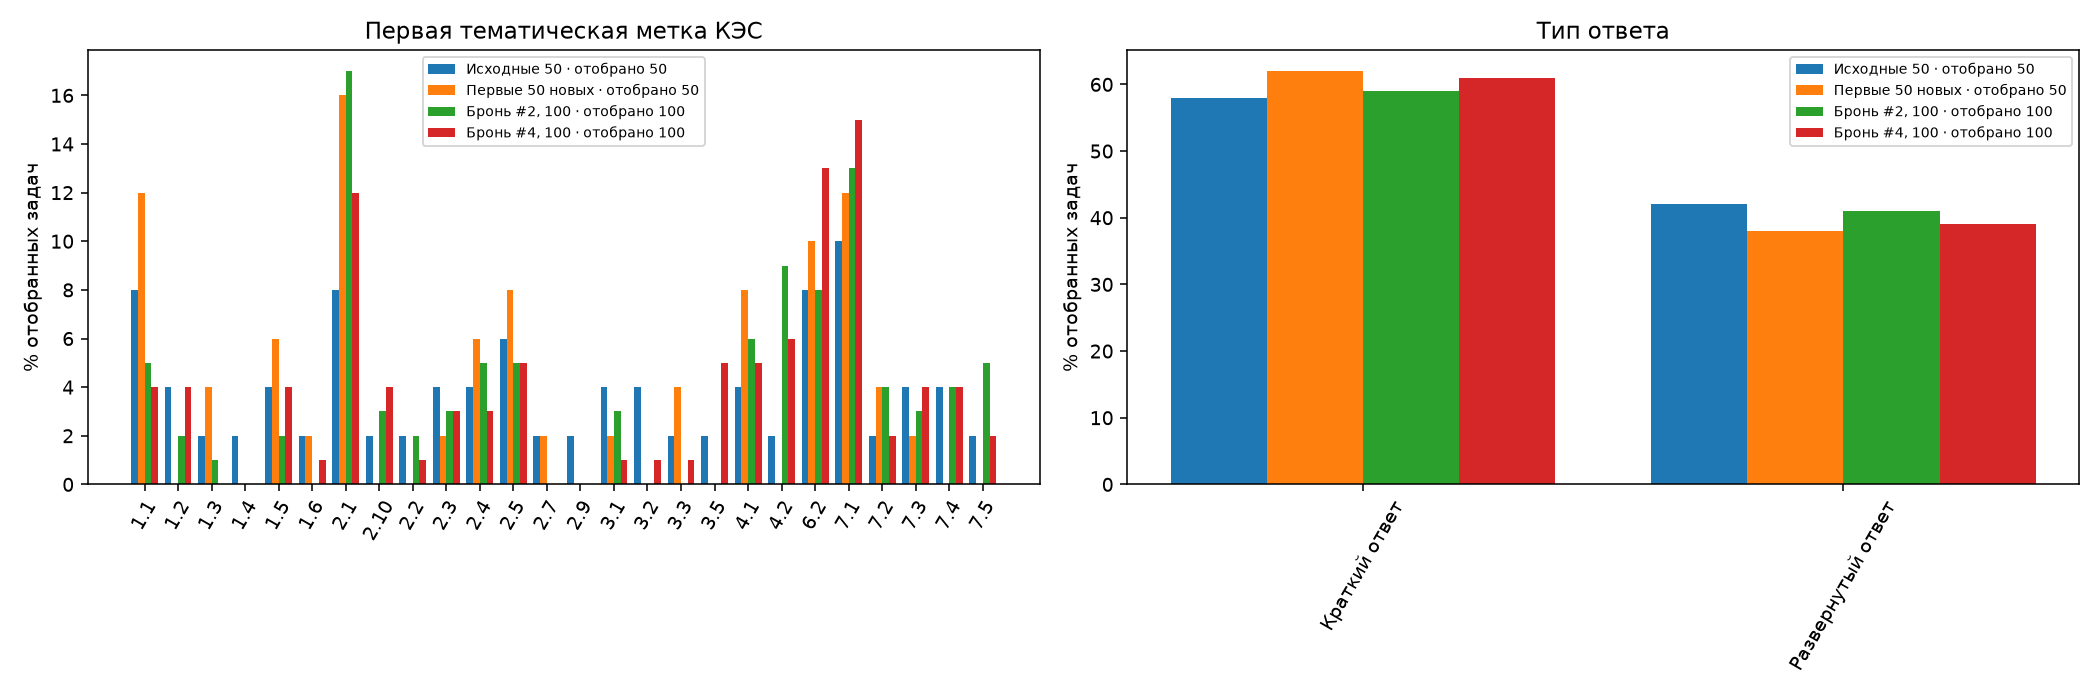

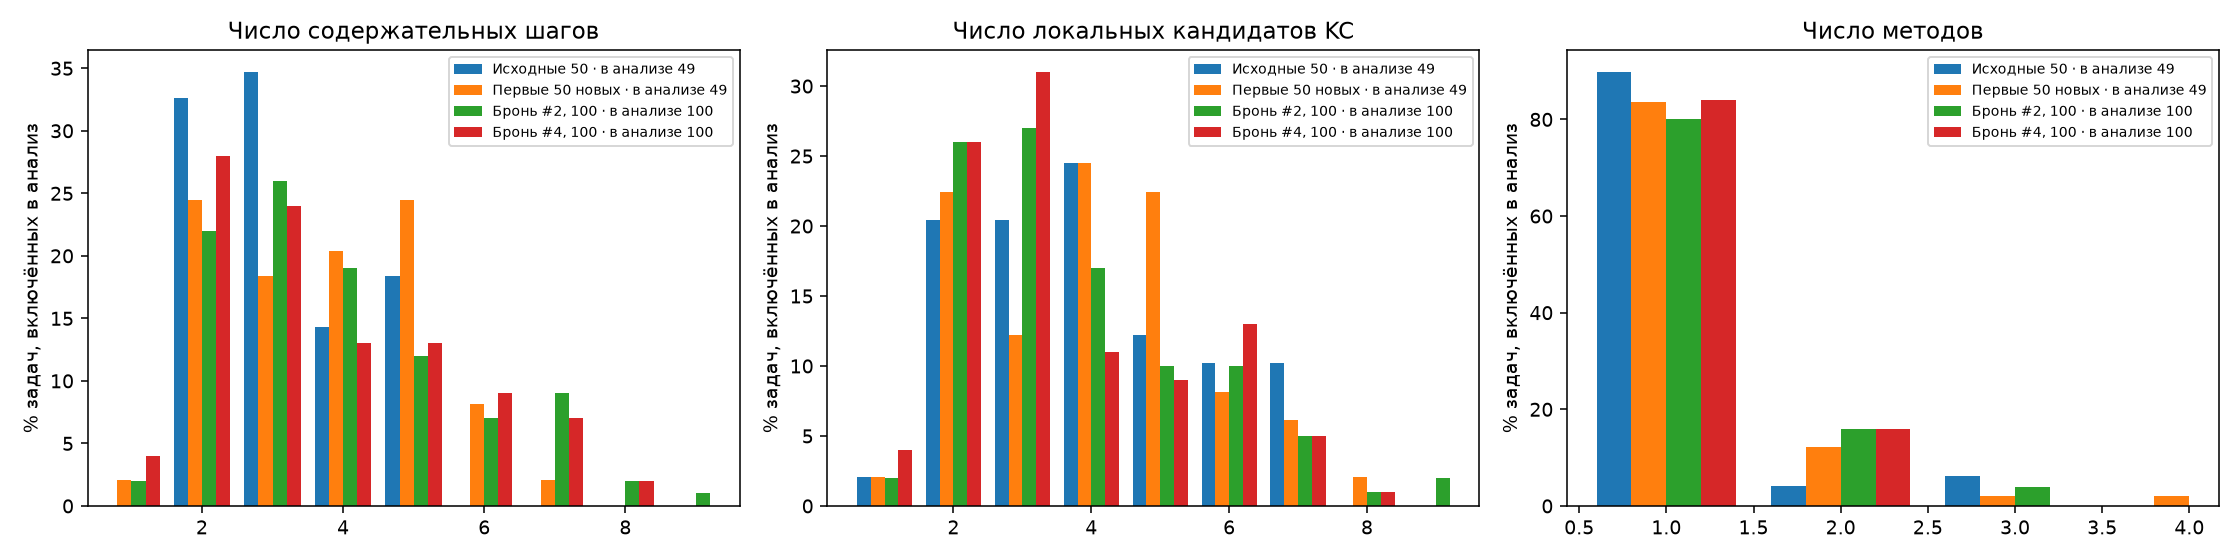

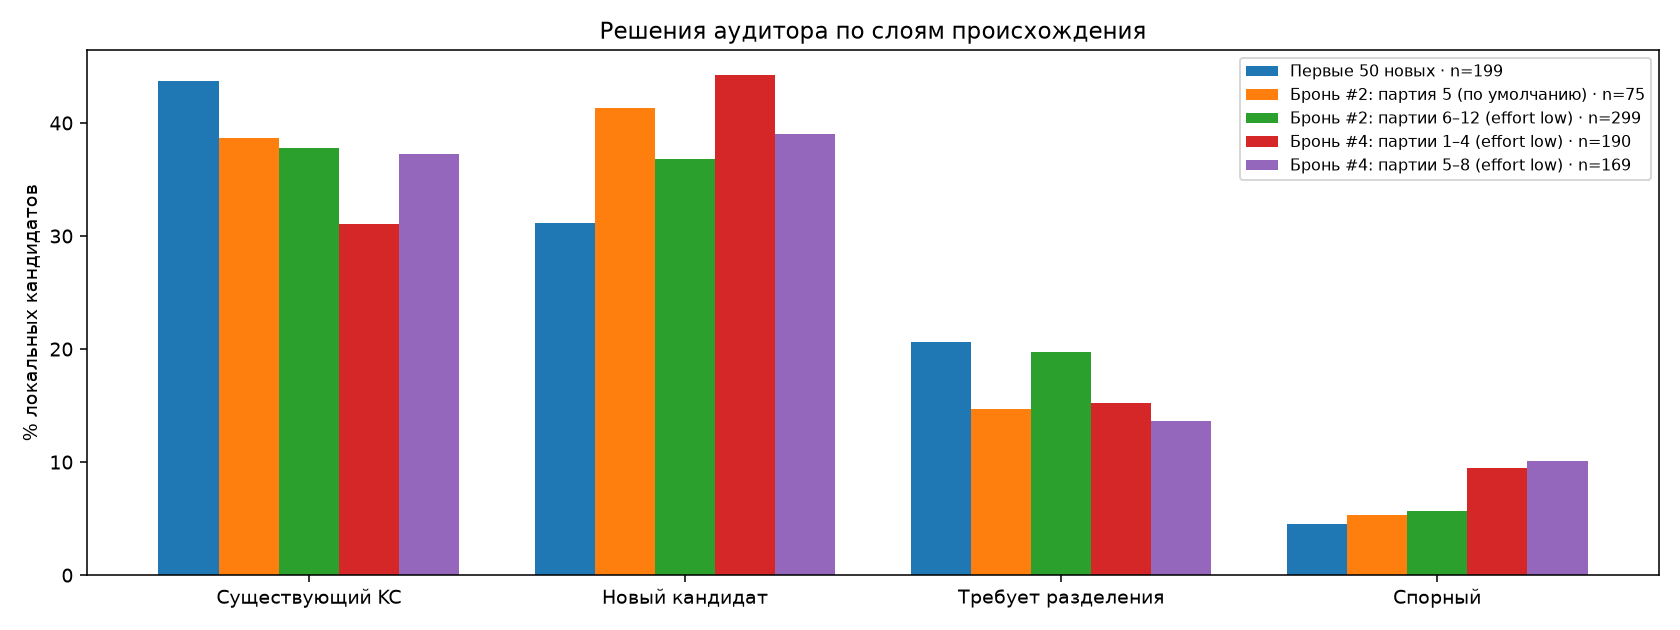

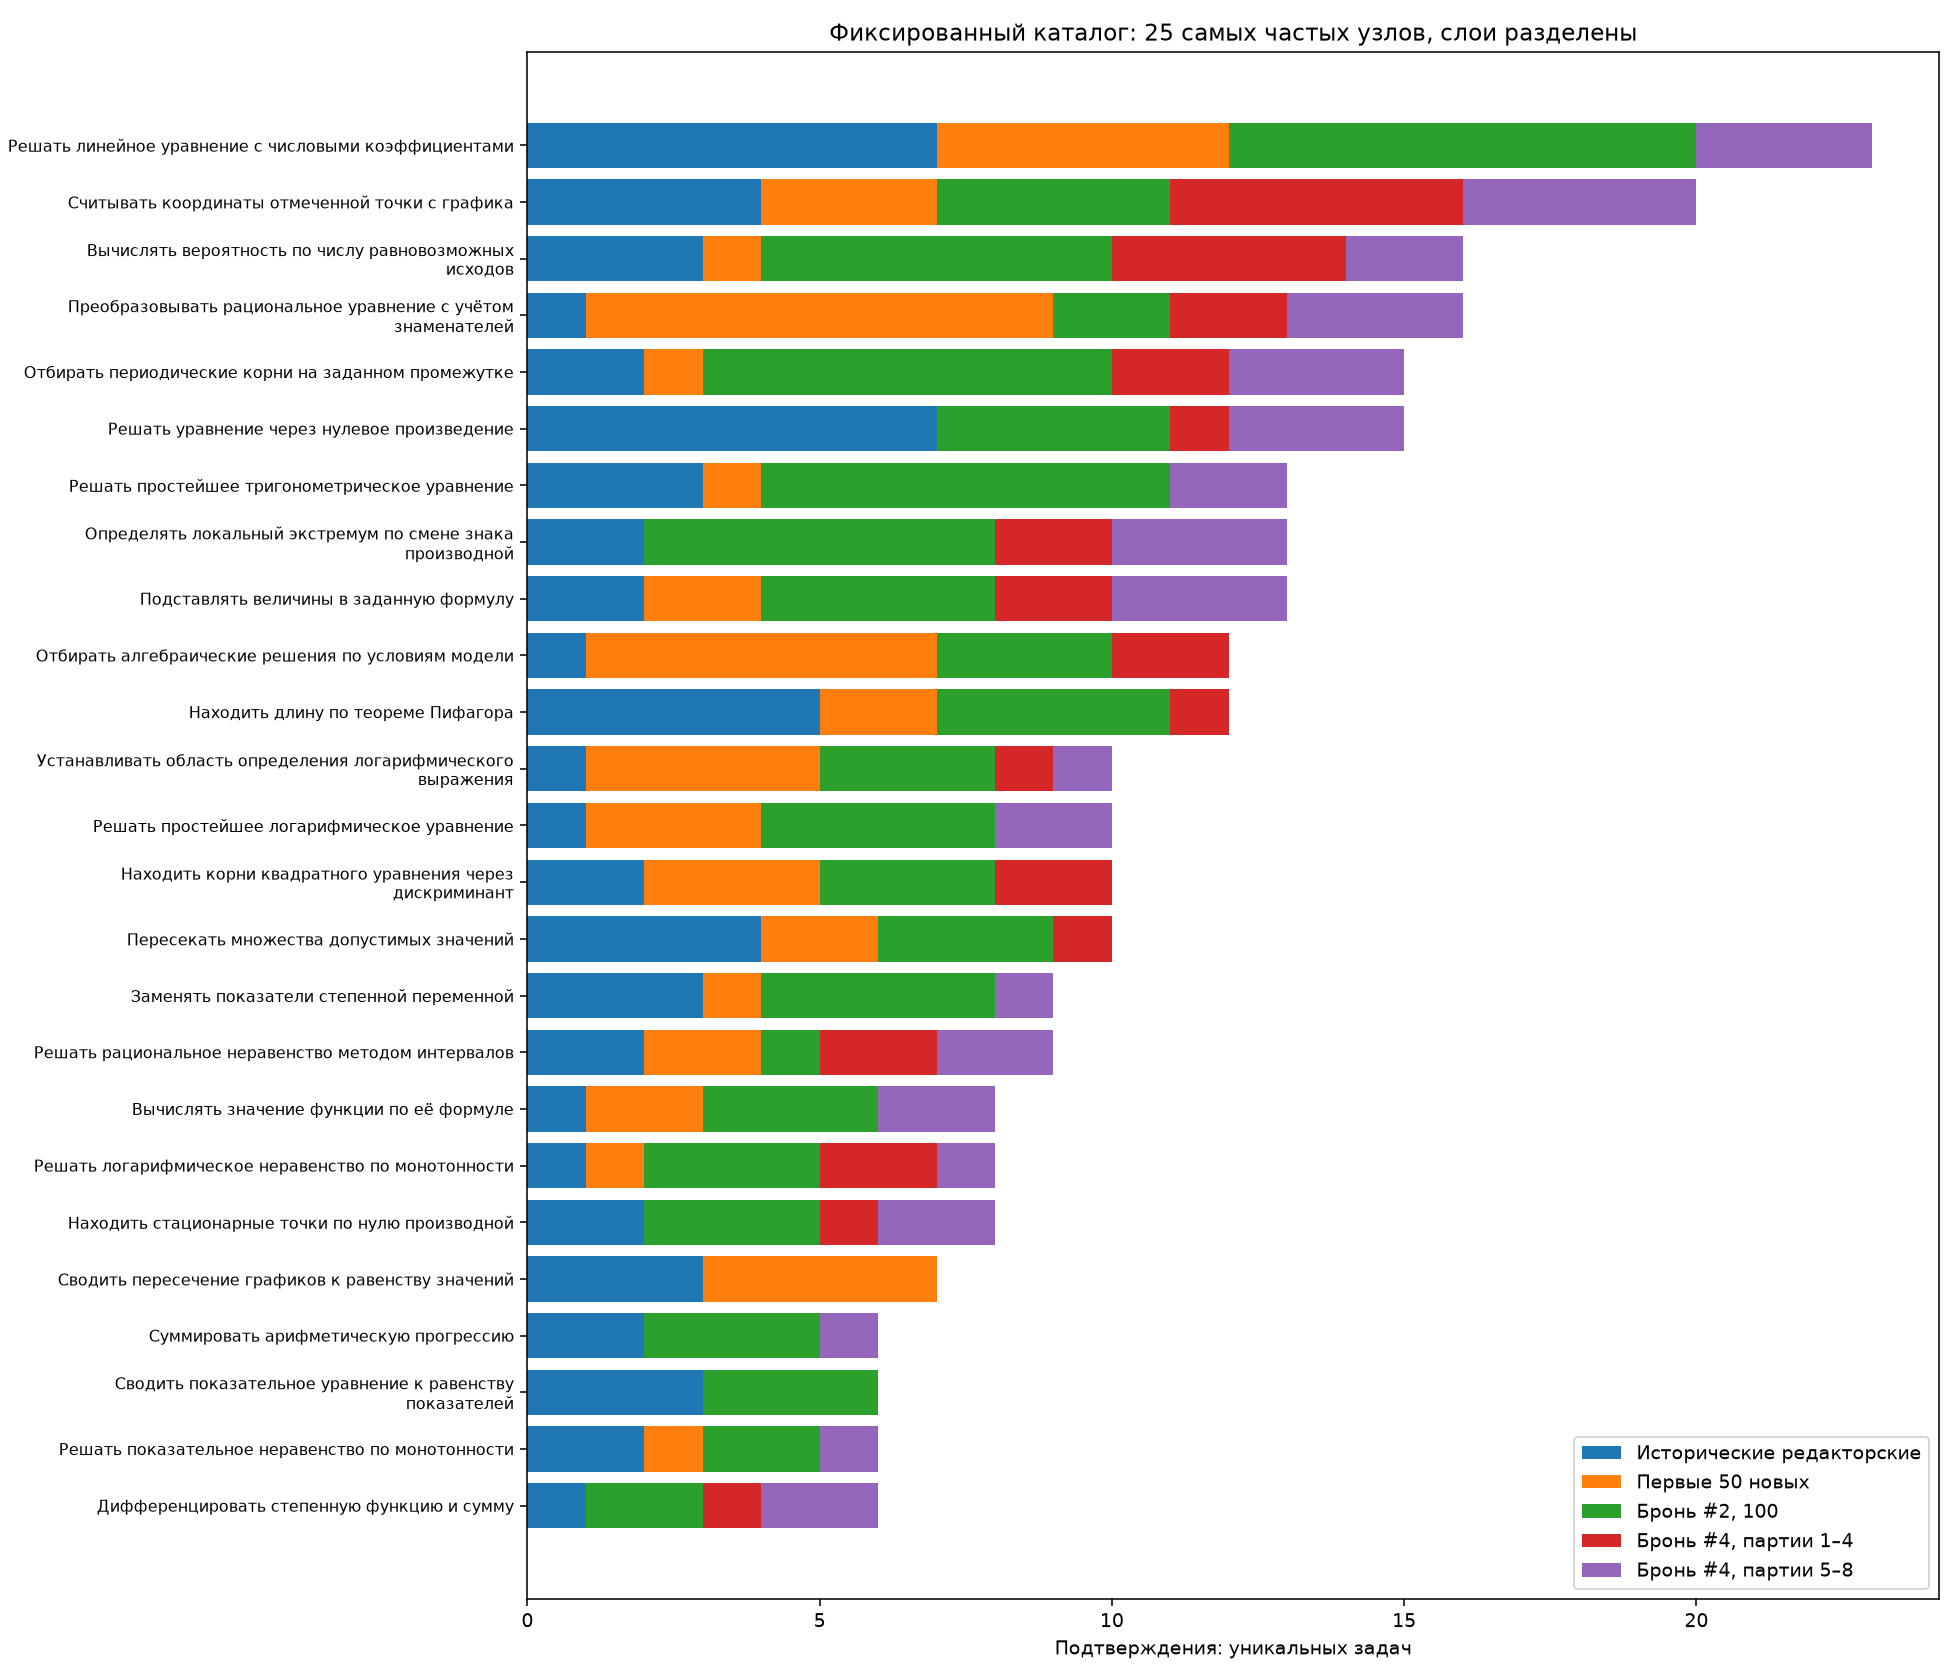

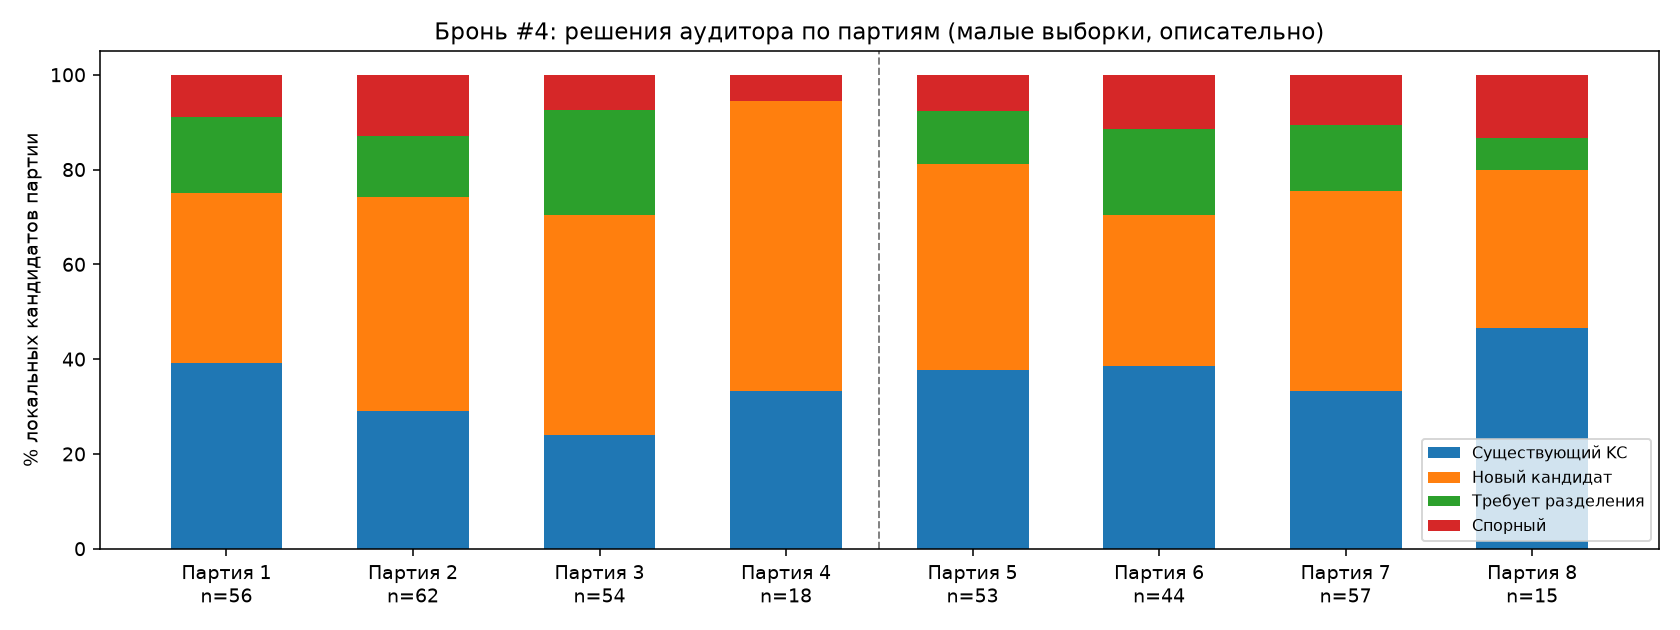

In [4]:
for name in cp.FIGURES:
    display(Image(filename=str(report_path / 'figures' / (name + '.png'))))
